# Point-in-time feature engineering — 14-day snapshot

**Question:** *Can information available early in an administrative case predict whether it will become a long-running case?*

This notebook builds one row per case containing **only information that would have been available 14 days after the case started**.
It follows the methodology fixed in `02b_target_definition.ipynb`:

| Locked decision | Value |
|---|---|
| Outcome cohort | cases with `case:endDate` present |
| Outcome duration | first logged event → last logged event (`event_log_days`) |
| Long-running | duration above the **training-period** 75th percentile (learned later, in modelling) |
| Prediction point | 14 days after the first logged event |
| Prediction population | cases still active after day 14 |
| Evaluation | chronological (later) |

"Long-running" is a **relative duration label**. It is not a legal delay, lateness or a performance judgement.

**Not done here:** no model, no tuning, no train/test split, no final label. The raw XES is read only.
The reusable logic lives in `src/features.py` (tested in `tests/test_features.py`); this notebook runs it, audits it and explains it.

# 1. Imports and paths

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm4py

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (folder for folder in candidates
     if (folder / "notebooks" / "01_data_loading.ipynb").is_file()
     and (folder / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from inside the capstone project.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src import features as F

xes_path = project_root / "data" / "raw" / "BPIC15_1.xes"
if not xes_path.is_file():
    raise FileNotFoundError("Place BPIC15_1.xes in data/raw/ before running this notebook.")
output_path = project_root / "data" / "processed" / "case_features_14d.csv"
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

EXPECTED_EVENT_ROWS, EXPECTED_CASES = 52_217, 1_199
EXPECTED_OUTCOME_ELIGIBLE, EXPECTED_PREDICTION_ELIGIBLE = 956, 917   # from 02b_target_definition.ipynb
print("Snapshot length (days):", F.SNAPSHOT_DAYS)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Snapshot length (days): 14


# 2. Load the event log

In [2]:
df = pm4py.convert_to_dataframe(pm4py.read_xes(str(xes_path), return_legacy_log_object=True))
df[F.EVENT_ORDER] = np.arange(len(df))   # position in the source file, used to break same-timestamp ties
n_events, n_cases = len(df), df[F.CASE].nunique()
print(f"Event rows: {n_events:,}   Cases: {n_cases:,}")
if (n_events, n_cases) != (EXPECTED_EVENT_ROWS, EXPECTED_CASES):
    raise RuntimeError("STOP: counts differ from the validated intake counts.")

C:\SPAR_CAPSTONE\.venv\Lib\site-packages\pm4py\utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


Event rows: 52,217   Cases: 1,199


# 3. Case timing and eligibility

For every case:

- `case_start` = first logged event, `case_end` = last logged event, `event_log_days` = `case_end − case_start`.
- `snapshot_time` = `case_start + 14 days` (exactly 14 × 24 hours).
- **Outcome-eligible:** `case:endDate` is present (the closure was recorded, so the final duration is known).
- **Prediction-eligible:** outcome-eligible **and** `case_end > snapshot_time` (logged activity after day 14).

**Why cases that finish by day 14 are excluded from prediction.** At the 14-day snapshot such a case is already over:
there is nothing left to predict, and no warning could change anything. Keeping them would also make the task artificially easy,
because "no activity after day 14" is itself the answer. They are all short cases, so excluding them only defines the population
the model is meant for: *cases still running at day 14*. They are not removed from the data, just not part of the prediction population.

In [3]:
timing = F.case_timing(df)
counts = pd.Series({
    "total cases": len(timing),
    "outcome-eligible (endDate present)": int(timing["outcome_eligible"].sum()),
    "not outcome-eligible (no endDate)": int((~timing["outcome_eligible"]).sum()),
    "prediction-eligible (active after day 14)": int(timing["prediction_eligible"].sum()),
    "excluded: finished by day 14": int((timing["outcome_eligible"] & ~timing["prediction_eligible"]).sum()),
}, name="cases")
display(counts.to_frame())
if (counts.iloc[1], counts.iloc[3]) != (EXPECTED_OUTCOME_ELIGIBLE, EXPECTED_PREDICTION_ELIGIBLE):
    raise RuntimeError("STOP: eligibility counts differ from 02b; investigate before continuing.")

finished_early = timing[timing["outcome_eligible"] & ~timing["prediction_eligible"]]
print(f"Event-log duration of the cases finished by day 14: max {finished_early['event_log_days'].max():.1f} days")

,cases
total cases,1199
outcome-eligible (endDate present),956
not outcome-eligible (no endDate),243
prediction-eligible (active after day 14),917
excluded: finished by day 14,39


Event-log duration of the cases finished by day 14: max 14.0 days


# 4. The 14-day snapshot

For each prediction-eligible case only events with `timestamp <= snapshot_time` are kept. Events are sorted deterministically by
case → timestamp → **original source order** (`event_order`).

> Timestamps in this log are mostly **date-level** (local midnight). Events on the same day therefore share a timestamp, and
> their relative order follows the source file. An event logged on the calendar day of the snapshot is included when its
> timestamp is at or before `snapshot_time`. Because the snapshot is exactly 14 × 24 hours, a case spanning a daylight-saving change
> can include or exclude day-14 midnight events by one hour; this applies the rule consistently and does not use future information.

In [4]:
events = F.prepare_events(df)
snap = F.snapshot_events(events, timing)
eligible_timing = timing[timing["prediction_eligible"]]
print(f"Events of prediction-eligible cases: {events[F.CASE].isin(eligible_timing.index).sum():,}")
print(f"Events kept in the 14-day snapshot:  {len(snap):,}")
print(f"Latest kept event relative to its snapshot (must be <= 0 days): "
      f"{((snap[F.TIMESTAMP] - snap['snapshot_time']).dt.total_seconds().max() / F.SECONDS_PER_DAY):.2f}")

example_case = eligible_timing.index[0]
example = events[events[F.CASE] == example_case].assign(
    in_snapshot=lambda t: t[F.TIMESTAMP] <= eligible_timing.loc[example_case, "snapshot_time"]
)
print(f"\nExample case {example_case}: snapshot at {eligible_timing.loc[example_case, 'snapshot_time']}")
display(example.head(15)[[F.TIMESTAMP, F.EVENT_ORDER, F.ACTIVITY, F.RESOURCE, "in_snapshot"]])

Events of prediction-eligible cases: 43,645
Events kept in the 14-day snapshot:  10,930
Latest kept event relative to its snapshot (must be <= 0 days): 0.00

Example case 10009138: snapshot at 2014-04-24 22:00:00+00:00


,time:timestamp,event_order,concept:name,org:resource,in_snapshot
0,2014-04-10 22:00:00+00:00,0,01_HOOFD_010,9264148,True
1,2014-04-13 22:00:00+00:00,1,01_HOOFD_011,9264148,True
2,2014-04-13 22:00:00+00:00,2,01_HOOFD_020,9264148,True
3,2014-04-13 22:00:00+00:00,3,02_DRZ_010,9264148,True
4,2014-04-13 22:00:00+00:00,4,04_BPT_005,9264148,True
5,2014-04-13 22:00:00+00:00,5,01_HOOFD_065_0,9264148,True
6,2014-04-13 22:00:00+00:00,6,01_HOOFD_110_0,9264148,True
7,2014-04-13 22:00:00+00:00,7,01_HOOFD_100_0,9264148,True
8,2014-04-13 22:00:00+00:00,8,01_HOOFD_015,9264148,True
9,2014-04-13 22:00:00+00:00,9,01_HOOFD_061,9264148,True


# 5. Build the feature table

`F.build_feature_table` runs the whole pipeline: timing → snapshot → features. It returns one row per prediction-eligible case.

In [5]:
features, activity_codes = F.build_feature_table(df)
predictors = F.predictor_columns(features)
numeric_predictors = [c for c in predictors if c not in F.CATEGORICAL_FEATURES]
print("Feature table shape:", features.shape)
print(f"Metadata columns ({len(F.METADATA_COLUMNS)}): {F.METADATA_COLUMNS}")
print(f"Predictors: {len(predictors)} ({len(numeric_predictors)} numeric incl. {len(activity_codes)} activity flags, "
      f"{len(F.CATEGORICAL_FEATURES)} categorical)")
display(features.head())

Feature table shape: (917, 47)
Metadata columns (6): ['case_id', 'case_start', 'snapshot_time', 'case_end', 'event_log_days', 'elapsed_days']
Predictors: 41 (39 numeric incl. 20 activity flags, 2 categorical)


,case_id,case_start,snapshot_time,case_end,event_log_days,elapsed_days,event_count_14d,unique_activity_count_14d,unique_resource_count_14d,repeated_event_count_14d,repeated_activity_count_14d,activities_repeated_more_than_once_14d,days_since_last_event,mean_inter_event_days,median_inter_event_days,max_inter_event_days,events_first_3_days,events_first_7_days,events_days_8_to_14,active_days_count_14d,events_per_active_day,resource_switch_count_14d,workload_cases_active_prev_30d,start_month,start_weekday,has_act_01_HOOFD_011,has_act_01_HOOFD_015,has_act_01_HOOFD_020,has_act_01_HOOFD_030_1,has_act_01_HOOFD_030_2,has_act_01_HOOFD_040,has_act_01_HOOFD_050,has_act_01_HOOFD_060,has_act_01_HOOFD_061,has_act_01_HOOFD_065_0,has_act_01_HOOFD_065_1,has_act_01_HOOFD_065_2,has_act_01_HOOFD_090,has_act_01_HOOFD_100_0,has_act_01_HOOFD_101,has_act_01_HOOFD_110_0,has_act_01_HOOFD_180,has_act_02_DRZ_010,has_act_04_BPT_005,has_act_05_EIND_010,first_activity,latest_activity_at_snapshot
0,10009138,2014-04-10 22:00:00+00:00,2014-04-24 22:00:00+00:00,2014-06-04 22:00:00+00:00,55.0,14.0,13,13,1,0,0,0,10.599109,0.283408,0.0,3.000000,1,13,0,2,6.5,0,66,4,4,1,1,1,1,1,0,0,0,1,1,0,0,0,1,1,1,0,1,1,0,01_HOOFD_010,01_HOOFD_030_2
1,10051383,2014-04-16 22:00:00+00:00,2014-04-30 22:00:00+00:00,2014-06-25 22:00:00+00:00,70.0,14.0,13,13,1,0,0,0,13.390127,0.050823,0.0,0.609873,13,13,0,1,13.0,0,65,4,3,1,1,1,1,1,0,0,0,1,1,0,0,0,1,1,1,0,1,1,0,OTHER,01_HOOFD_030_2
2,10053042,2014-04-13 22:00:00+00:00,2014-04-27 22:00:00+00:00,2014-07-02 22:00:00+00:00,80.0,14.0,13,13,1,0,0,0,10.375428,0.302048,0.0,3.000000,1,13,0,2,6.5,0,63,4,0,1,1,1,1,1,0,0,0,1,1,0,0,0,1,1,1,0,1,1,0,01_HOOFD_010,01_HOOFD_030_2
3,10093171,2014-04-21 22:00:00+00:00,2014-05-05 22:00:00+00:00,2014-07-09 22:00:00+00:00,79.0,14.0,12,12,1,0,0,0,6.472326,0.684334,0.0,7.000000,1,1,11,2,6.0,0,60,4,1,1,1,1,1,1,0,0,0,1,1,0,0,0,1,1,0,0,1,1,0,01_HOOFD_010,01_HOOFD_030_2
4,10186644,2014-04-30 22:00:00+00:00,2014-05-14 22:00:00+00:00,2014-06-25 22:00:00+00:00,56.0,14.0,13,13,1,0,0,0,0.000000,1.166667,0.0,14.000000,1,1,12,2,6.5,0,59,5,3,1,1,1,1,0,0,0,0,1,1,0,0,1,1,1,1,0,1,1,0,01_HOOFD_010,OTHER


### 5.1 Early-activity features: the selection rule

`activityNameEN` is **not one-to-one** with activity codes (one English name is used by several codes, and a few codes carry
several English names; see `02_eda.ipynb`). The **activity code** (`concept:name`) is therefore the reliable key, and the English name
is attached only as a readable label.

**Rule (frequency only, no outcome information):** a 0/1 flag `has_act_<code>` is created for every code observed by day 14 in
**10%–90% of prediction-eligible cases**.

- Codes in more than 90% of cases barely vary (e.g. the registration step), so they carry almost no information.
- Codes in fewer than 10% of cases are too rare to estimate reliably.
- No code is chosen because of its relation to the outcome.

The share is computed on all prediction-eligible cases. The modelling step can re-run `F.select_activity_codes` on the training
period only, if desired.

`first_activity` and `latest_activity_at_snapshot` are kept as categorical codes; values seen in fewer than 20 cases are grouped into `OTHER`.

In [6]:
english_label = df.groupby(F.ACTIVITY)["activityNameEN"].agg(lambda s: s.value_counts().index[0])
code_share = snap.groupby(F.ACTIVITY)[F.CASE].nunique() / snap[F.CASE].nunique()
display(pd.DataFrame({
    "english_name": english_label.reindex(activity_codes),
    "share_of_cases_by_day_14": code_share.reindex(activity_codes).round(3),
}).sort_values("share_of_cases_by_day_14", ascending=False))
print(f"Codes above 90% (excluded as near-constant): {list(code_share[code_share > F.ACTIVITY_MAX_CASE_SHARE].index)}")
print(f"Codes below 10% (excluded as rare): {int((code_share < F.ACTIVITY_MIN_CASE_SHARE).sum())}")
for column in F.CATEGORICAL_FEATURES:
    print(f"\n{column}:")
    print(features[column].value_counts().to_string())

,english_name,share_of_cases_by_day_14
concept:name,,
01_HOOFD_015,phase application received,0.885
01_HOOFD_020,send confirmation receipt,0.885
01_HOOFD_030_1,send confirmation receipt,0.811
01_HOOFD_030_2,enter senddate acknowledgement,0.805
01_HOOFD_011,OLO messaging active,0.629
02_DRZ_010,forward to the competent authority,0.615
04_BPT_005,regular procedure without MER,0.605
01_HOOFD_101,registration date publication,0.603
01_HOOFD_061,start WABOprocedure,0.459


Codes above 90% (excluded as near-constant): ['01_HOOFD_010']
Codes below 10% (excluded as rare): 126

first_activity:
first_activity
01_HOOFD_010    872
01_HOOFD_011     23
OTHER            22

latest_activity_at_snapshot:
latest_activity_at_snapshot
OTHER             227
01_HOOFD_030_2    220
01_HOOFD_101      215
01_HOOFD_065_2     59
01_HOOFD_010       55
01_HOOFD_100       43
01_HOOFD_030_1     39
01_HOOFD_100_0     32
01_HOOFD_060       27


### 5.2 Feature dictionary

In [7]:
feature_docs = {
    "event_count_14d": ("events", "Events logged by day 14"),
    "unique_activity_count_14d": ("events", "Distinct activity codes by day 14"),
    "unique_resource_count_14d": ("resources", "Distinct resources involved by day 14"),
    "repeated_event_count_14d": ("rework", "Events repeating an activity already seen (events − distinct activities)"),
    "repeated_activity_count_14d": ("rework", "Distinct activities occurring at least twice"),
    "activities_repeated_more_than_once_14d": ("rework", "Distinct activities occurring three or more times (repeated more than once)"),
    "days_since_last_event": ("timing", "Days between the last observed event and the snapshot (current waiting time)"),
    "mean_inter_event_days": ("timing", "Mean gap between consecutive events (0 if only one event)"),
    "median_inter_event_days": ("timing", "Median gap between consecutive events (0 if only one event)"),
    "max_inter_event_days": ("timing", "Longest gap between consecutive events (0 if only one event)"),
    "events_first_3_days": ("rhythm", "Events on calendar days 0–2 after the start"),
    "events_first_7_days": ("rhythm", "Events on calendar days 0–6 after the start"),
    "events_days_8_to_14": ("rhythm", "Events on days 7–14 (8th day up to the snapshot)"),
    "active_days_count_14d": ("rhythm", "Distinct local calendar days with at least one event"),
    "events_per_active_day": ("rhythm", "Events divided by active days"),
    "resource_switch_count_14d": ("resources", "Consecutive events with different resources (hand-overs; not a performance measure)"),
    "workload_cases_active_prev_30d": ("context", "Other cases with any event in the 30 days before the snapshot (only past events)"),
    "start_month": ("context", "Calendar month of the first event (local time)"),
    "start_weekday": ("context", "Weekday of the first event (0 = Monday)"),
    "first_activity": ("early path", "Activity code of the first event (rare -> OTHER)"),
    "latest_activity_at_snapshot": ("early path", "Activity code of the last event observed by day 14 (rare -> OTHER)"),
}
for activity in activity_codes:
    feature_docs[F.ACTIVITY_FLAG_PREFIX + activity] = ("early path", f"1 if '{english_label[activity]}' ({activity}) occurred by day 14")
dictionary = pd.DataFrame.from_dict(feature_docs, orient="index", columns=["group", "description"])
dictionary.index.name = "feature"
assert set(dictionary.index) == set(predictors), "every predictor must be documented"
display(dictionary.loc[predictors])

,group,description
feature,,
event_count_14d,events,Events logged by day 14
unique_activity_count_14d,events,Distinct activity codes by day 14
unique_resource_count_14d,resources,Distinct resources involved by day 14
repeated_event_count_14d,rework,Events repeating an activity already seen (events − distinct activities)
repeated_activity_count_14d,rework,Distinct activities occurring at least twice
activities_repeated_more_than_once_14d,rework,Distinct activities occurring three or more times (repeated more than once)
days_since_last_event,timing,Days between the last observed event and the snapshot (current waiting time)
mean_inter_event_days,timing,Mean gap between consecutive events (0 if only one event)
median_inter_event_days,timing,Median gap between consecutive events (0 if only one event)


# 6. Planned / due fields — point-in-time audit

The event-level fields `planned` and `dueDate` would only be usable if their **values** were known when the event was logged.
An event that happened before day 14 does not prove that the value attached to it was written before day 14: the XES is an
extract of the system's final state, and attributes may have been filled in or updated later. The evidence below checks this.

In [8]:
snapshot_rows = df[df[F.CASE].isin(eligible_timing.index)].copy()
snapshot_rows["snapshot_time"] = snapshot_rows[F.CASE].map(eligible_timing["snapshot_time"])
snapshot_rows = snapshot_rows[snapshot_rows[F.TIMESTAMP] <= snapshot_rows["snapshot_time"]]

date_finished = pd.to_datetime(snapshot_rows["dateFinished"]).dt.tz_localize(F.LOCAL_TIMEZONE, ambiguous="NaT", nonexistent="NaT")
planned_offset = (snapshot_rows["planned"] - snapshot_rows[F.TIMESTAMP]).dt.total_seconds() / F.SECONDS_PER_DAY
due_offset = (snapshot_rows["dueDate"] - snapshot_rows[F.TIMESTAMP]).dt.total_seconds() / F.SECONDS_PER_DAY
has_time_of_day = lambda s: ((s.dt.tz_convert(F.LOCAL_TIMEZONE).dt.hour != 0) | (s.dt.tz_convert(F.LOCAL_TIMEZONE).dt.minute != 0))

evidence = pd.Series({
    "events observed by day 14": len(snapshot_rows),
    "dateFinished LATER than the snapshot": int((date_finished > snapshot_rows["snapshot_time"]).sum()),
    "planned present": int(snapshot_rows["planned"].notna().sum()),
    "planned with a time of day (event timestamps are dates)": int(has_time_of_day(snapshot_rows["planned"].dropna()).sum()),
    "planned BEFORE its own event date (by > 1 day)": int((planned_offset < -1).sum()),
    "planned AFTER the snapshot": int((snapshot_rows["planned"] > snapshot_rows["snapshot_time"]).sum()),
    "dueDate present": int(snapshot_rows["dueDate"].notna().sum()),
    "dueDate min offset from event (days)": round(due_offset.min(), 1),
    "dueDate max offset from event (days)": round(due_offset.max(), 1),
}, name="value")
display(evidence.to_frame())

,value
events observed by day 14,10930.0
dateFinished LATER than the snapshot,1276.0
planned present,9159.0
planned with a time of day (event timestamps are dates),9159.0
planned BEFORE its own event date (by > 1 day),169.0
planned AFTER the snapshot,727.0
dueDate present,2284.0
dueDate min offset from event (days),-151.4
dueDate max offset from event (days),459.7


**Decision: `planned`, `dueDate`, `dateFinished`, `dateStop` and `case:endDatePlanned` are all EXCLUDED.**

- `dateFinished` proves the core problem: many events observed by day 14 carry a `dateFinished` **after** day 14. Event attributes in this extract can therefore hold information written later than the event itself.
- `planned` has second-level precision while event timestamps are dates, and is sometimes *before* its own event. It looks like a system/task timestamp whose write time is unknown.
- `dueDate` offsets range from months before to more than a year after the event, which is hard to reconcile with a value fixed when the step was logged. It may have been updated.
- `dateStop` is almost empty; `case:endDatePlanned` is case-level, sparse and often equals the final `endDate` (see `02_eda.ipynb`).

Without documentation of **when** these values are written, any feature built on them could carry future information.
Correctness is preferred over feature count.

# 7. Case-level attributes — are any known at case start?

`case:*` attributes have **one value per case, as of extraction**, with no timestamp. A value is only safe if it is plausibly fixed
when the case starts. **UNCLEAR is excluded by default.**

In [9]:
case_attribute_audit = pd.DataFrame([
    ("case:termName", "UNSAFE", "Names of legal terms, incl. ones only reached after a decision (objection/appeal term); reflects the state at extraction"),
    ("case:parts", "UNCLEAR", "Permit components requested; plausibly from the application, but may be amended during handling and has no timestamp"),
    ("case:SUMleges", "UNCLEAR", "A fee total; likely calculated at or after the decision"),
    ("case:Includes_subCases", "UNCLEAR", "Sub-cases are created during handling (activity 'create subcases completeness' occurs over time)"),
    ("case:Responsible_actor", "UNCLEAR", "A single final value; the assignment may change during the case"),
    ("case:caseProcedure", "UNSAFE", "Regular vs extended procedure can change ('procedure change' activity); the attribute holds the final value"),
    ("case:case_type", "EXCLUDED", "Constant (one value) — carries no information"),
    ("case:landRegisterID, case:IDofConceptCase", "EXCLUDED", "Identifiers, not process information"),
    ("case:startDate", "SAFE (not needed)", "Known at start; equals the first event date in ~98% of cases, so the first event is used for timing"),
    ("case:endDate", "UNSAFE", "Completion date (final state); used only for outcome eligibility"),
    ("case:endDatePlanned", "UNSAFE", "Sparse; often equals endDate; write time unknown"),
    ("case:caseStatus", "UNSAFE", "Status at extraction (final state)"),
    ("case:last_phase", "UNSAFE", "Phase at extraction (final state)"),
    ("case:requestComplete", "UNSAFE", "Snapshot value with unknown timing"),
], columns=["attribute", "classification", "reason"])
case_attribute_audit["used_as_predictor"] = case_attribute_audit["classification"].eq("SAFE")
display(case_attribute_audit)
print("Case-level attributes used as predictors:", int(case_attribute_audit["used_as_predictor"].sum()))

,attribute,classification,reason,used_as_predictor
0,case:termName,UNSAFE,"Names of legal terms, incl. ones only reached after a decision (objection/appeal term)...",False
1,case:parts,UNCLEAR,"Permit components requested; plausibly from the application, but may be amended during...",False
2,case:SUMleges,UNCLEAR,A fee total; likely calculated at or after the decision,False
3,case:Includes_subCases,UNCLEAR,Sub-cases are created during handling (activity 'create subcases completeness' occurs ...,False
4,case:Responsible_actor,UNCLEAR,A single final value; the assignment may change during the case,False
5,case:caseProcedure,UNSAFE,Regular vs extended procedure can change ('procedure change' activity); the attribute ...,False
6,case:case_type,EXCLUDED,Constant (one value) — carries no information,False
7,"case:landRegisterID, case:IDofConceptCase",EXCLUDED,"Identifiers, not process information",False
8,case:startDate,SAFE (not needed),"Known at start; equals the first event date in ~98% of cases, so the first event is us...",False
9,case:endDate,UNSAFE,Completion date (final state); used only for outcome eligibility,False


Case-level attributes used as predictors: 0


No case-level attribute is used. `case:parts` is the most promising candidate for later work (it plausibly comes from the application);
it should be added only if its timing can be confirmed. Other event-level fields are also excluded: `question` (mixed free content
with an `EMPTY` placeholder; meaning unknown), `monitoringResource` (meaning unknown), `activityNameNL`/`action_code` (duplicates
of the activity name/code), `lifecycle:transition` (constant).

# 8. Leakage audit

### 8.1 Every engineered predictor

In [10]:
source_columns = {
    "events": "case:concept:name, time:timestamp", "rework": "concept:name", "timing": "time:timestamp",
    "rhythm": "time:timestamp", "resources": "org:resource, time:timestamp", "early path": "concept:name, time:timestamp",
    "context": "time:timestamp (first event of this case)",
}
workload_source = "case:concept:name, time:timestamp of all cases' events <= this case's snapshot"
leakage_audit = pd.DataFrame({
    "feature_name": dictionary.index,
    "source_columns": dictionary["group"].map(source_columns).to_numpy(),
    "available_by_day_14": "YES",
    "future_information_used": "NO",
    "decision": "KEEP",
    "reason": "computed only from events with timestamp <= snapshot_time",
})
leakage_audit.loc[leakage_audit["feature_name"].isin(["start_month", "start_weekday"]), "reason"] = "date of the first event, known at case start"
leakage_audit.loc[leakage_audit["feature_name"] == "workload_cases_active_prev_30d", "source_columns"] = workload_source
excluded_rows = pd.DataFrame([
    ("elapsed_days", "snapshot definition", "YES", "NO", "METADATA", "constant 14 for every case — no information"),
    ("start year", "time:timestamp", "YES", "NO", "EXCLUDE", "would let a chronological model extrapolate on calendar year (drift proxy)"),
    ("event_log_days", "final event time", "NO", "YES", "OUTCOME ONLY", "defines the label"),
    ("case_end / last event time", "time:timestamp (all events)", "NO", "YES", "OUTCOME ONLY", "end of the full trace"),
    ("final event / activity / resource counts", "full trace", "NO", "YES", "EXCLUDE", "need events after day 14"),
    ("full trace / process variant / last activity", "full trace", "NO", "YES", "EXCLUDE", "need events after day 14"),
    ("planned, dueDate, dateFinished, dateStop", "event attributes", "UNCLEAR", "POSSIBLE", "EXCLUDE", "write time unknown (Section 6)"),
    ("case:* attributes", "case attributes", "UNCLEAR/NO", "POSSIBLE", "EXCLUDE", "see Section 7"),
], columns=leakage_audit.columns)
full_audit = pd.concat([leakage_audit, excluded_rows], ignore_index=True)
display(full_audit)
kept = full_audit[full_audit["decision"] == "KEEP"]
assert (kept["available_by_day_14"] == "YES").all() and (kept["future_information_used"] == "NO").all()
assert set(kept["feature_name"]) == set(predictors)

,feature_name,source_columns,available_by_day_14,future_information_used,decision,reason
0,event_count_14d,"case:concept:name, time:timestamp",YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
1,unique_activity_count_14d,"case:concept:name, time:timestamp",YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
2,unique_resource_count_14d,"org:resource, time:timestamp",YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
3,repeated_event_count_14d,concept:name,YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
4,repeated_activity_count_14d,concept:name,YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
5,activities_repeated_more_than_once_14d,concept:name,YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
6,days_since_last_event,time:timestamp,YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
7,mean_inter_event_days,time:timestamp,YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
8,median_inter_event_days,time:timestamp,YES,NO,KEEP,computed only from events with timestamp <= snapshot_time
9,max_inter_event_days,time:timestamp,YES,NO,KEEP,computed only from events with timestamp <= snapshot_time


### 8.2 Automated checks

1. **Forbidden content:** no predictor name refers to final-state or outcome information.
2. **Snapshot bound:** every event used for per-case features is at or before its case's snapshot.
3. **Future-perturbation test:** every event **after** each case's snapshot is overwritten with fake activities and resources and
   moved one year later; the per-case predictors must be **identical**.
4. **Workload check:** the workload feature is recomputed independently using only events at or before each snapshot.

In [11]:
forbidden_fragments = ["endDate", "end_date", "case_end", "event_log_days", "requestComplete", "last_phase", "caseStatus",
                       "variant", "final", "total", "dueDate", "planned", "dateFinished", "dateStop"]
assert not [p for p in predictors if any(fragment.lower() in p.lower() for fragment in forbidden_fragments)]
assert not set(predictors) & set(F.METADATA_COLUMNS)
print("1. No forbidden or metadata columns among predictors.")

assert (snap[F.TIMESTAMP] <= snap["snapshot_time"]).all()
print("2. All snapshot events are at or before their snapshot.")

after_snapshot = df[F.TIMESTAMP] > df[F.CASE].map(timing["snapshot_time"])
perturbed = df.copy()
perturbed.loc[after_snapshot, F.ACTIVITY] = "FAKE_FUTURE_ACTIVITY"
perturbed.loc[after_snapshot, F.RESOURCE] = "FAKE_FUTURE_RESOURCE"
perturbed.loc[after_snapshot, F.TIMESTAMP] = perturbed.loc[after_snapshot, F.TIMESTAMP] + pd.Timedelta(days=365)
perturbed_features, _ = F.build_feature_table(perturbed, activity_codes=activity_codes)
per_case_predictors = [p for p in predictors if p != "workload_cases_active_prev_30d"]
pd.testing.assert_frame_equal(
    features.set_index("case_id")[per_case_predictors],
    perturbed_features.set_index("case_id").loc[features["case_id"], per_case_predictors],
)
print(f"3. Perturbation test passed: {int(after_snapshot.sum()):,} future events altered, per-case predictors unchanged.")

1. No forbidden or metadata columns among predictors.
2. All snapshot events are at or before their snapshot.


3. Perturbation test passed: 37,550 future events altered, per-case predictors unchanged.


In [12]:
event_times = df[[F.CASE, F.TIMESTAMP]]
independent = {}
for case_id, snapshot in eligible_timing["snapshot_time"].items():
    window = event_times[(event_times[F.TIMESTAMP] > snapshot - pd.Timedelta(days=F.WORKLOAD_WINDOW_DAYS))
                         & (event_times[F.TIMESTAMP] <= snapshot) & (event_times[F.CASE] != case_id)]
    independent[case_id] = window[F.CASE].nunique()
assert features.set_index("case_id")["workload_cases_active_prev_30d"].equals(
    pd.Series(independent, dtype="int64").reindex(features["case_id"]).rename("workload_cases_active_prev_30d").rename_axis("case_id"))
print("4. Workload feature matches an independent past-only recomputation.")

4. Workload feature matches an independent past-only recomputation.


# 9. Data-quality checks

In [13]:
assert features["case_id"].is_unique, "duplicate case_id"
assert set(features["case_id"]) == set(eligible_timing.index), "prediction-eligible case missing or extra"
assert (features["case_end"] > features["snapshot_time"]).all()
numeric_block = features[numeric_predictors]
assert np.isfinite(numeric_block.to_numpy(dtype=float)).all(), "non-finite values"
print("One row per prediction-eligible case:", len(features) == len(eligible_timing))
print("Missing values per column (all columns):", int(features.isna().sum().sum()))

ranges = numeric_block.describe().T[["min", "50%", "max"]]
display(ranges)
assert (numeric_block >= 0).all().all(), "negative values"
assert (features["days_since_last_event"] <= F.SNAPSHOT_DAYS).all()
assert (features["max_inter_event_days"] <= F.SNAPSHOT_DAYS).all()
assert (features["events_first_3_days"] <= features["events_first_7_days"]).all()
assert (features["events_first_7_days"] + features["events_days_8_to_14"] == features["event_count_14d"]).all()
assert (features["unique_activity_count_14d"] <= features["event_count_14d"]).all()
print("Range checks passed.")
zero_variance = [c for c in numeric_predictors if features[c].nunique() == 1]
print("Predictors with a single value in this data (no information; kept for completeness, the modelling step may drop them):", zero_variance)

type_counts = pd.Series({
    "numeric (counts, timing, context)": len(F.CORE_NUMERIC_FEATURES),
    "numeric binary (activity flags)": len(activity_codes),
    "categorical": len(F.CATEGORICAL_FEATURES),
    "metadata / outcome (not predictors)": len(F.METADATA_COLUMNS),
    "excluded items listed in the audit tables (Sections 7–8)": len(excluded_rows) - 1 + len(case_attribute_audit[~case_attribute_audit["used_as_predictor"]]),
}, name="count")
display(type_counts.to_frame())

One row per prediction-eligible case: True
Missing values per column (all columns): 0


,min,50%,max
event_count_14d,1.0,12.000000,49.0
unique_activity_count_14d,1.0,12.000000,49.0
unique_resource_count_14d,1.0,1.000000,3.0
repeated_event_count_14d,0.0,0.000000,2.0
repeated_activity_count_14d,0.0,0.000000,2.0
activities_repeated_more_than_once_14d,0.0,0.000000,0.0
days_since_last_event,0.0,8.547176,14.0
mean_inter_event_days,0.0,0.451835,14.0
median_inter_event_days,0.0,0.000023,14.0
max_inter_event_days,0.0,5.000000,14.0


Range checks passed.
Predictors with a single value in this data (no information; kept for completeness, the modelling step may drop them): ['activities_repeated_more_than_once_14d']


,count
"numeric (counts, timing, context)",19
numeric binary (activity flags),20
categorical,2
metadata / outcome (not predictors),6
excluded items listed in the audit tables (Sections 7–8),21


# 10. Save the feature dataset

Saved as **CSV** (no Parquet engine is installed and no dependency was added). Timestamps are written in ISO-8601 with a UTC
offset; `F.load_features_csv` restores the dtypes. The file is in `data/processed/`, which is git-ignored.

The outcome is stored as the **raw duration** (`event_log_days`). No label is saved, so the modelling step can derive the label
from the **training-period** P75 without leakage.

In [14]:
F.save_features_csv(features, output_path)
reloaded = F.load_features_csv(output_path)
assert reloaded.shape == features.shape
assert reloaded["case_start"].equals(features["case_start"].astype(reloaded["case_start"].dtype))
assert np.allclose(reloaded[numeric_predictors].to_numpy(dtype=float), features[numeric_predictors].to_numpy(dtype=float))
print("Saved:", output_path.relative_to(project_root), "| shape", reloaded.shape, "| round-trip OK")

Saved: data\processed\case_features_14d.csv | shape (917, 47) | round-trip OK


# 11. Exploratory comparison (descriptive, NON-FINAL label)

To get a feel for the features, cases are split with a **provisional, NON-FINAL** label: event-log duration above the P75 of the
outcome-eligible cohort, computed here only for description. **It is not saved, not the modelling label, and not used to select features.**
Differences are **associations, not causes**.

In [15]:
provisional_threshold = timing.loc[timing["outcome_eligible"], "event_log_days"].quantile(0.75)
provisional_group = np.where(features["event_log_days"] > provisional_threshold, "longer-running", "shorter-running")
print(f"Provisional (NON-FINAL) threshold: {provisional_threshold:.2f} days")
print(pd.Series(provisional_group).value_counts().to_string())

by_group = features[numeric_predictors].groupby(provisional_group)
comparison = pd.DataFrame({
    "median shorter": by_group.median().loc["shorter-running"],
    "median longer": by_group.median().loc["longer-running"],
    "mean shorter": by_group.mean().loc["shorter-running"],
    "mean longer": by_group.mean().loc["longer-running"],
})
print("For 0/1 activity flags the mean is the share of cases in which the activity occurred by day 14.")
display(comparison.round(2))

Provisional (NON-FINAL) threshold: 102.53 days
shorter-running    678
longer-running     239
For 0/1 activity flags the mean is the share of cases in which the activity occurred by day 14.


,median shorter,median longer,mean shorter,mean longer
event_count_14d,12.00,11.00,12.62,9.93
unique_activity_count_14d,12.00,11.00,12.59,9.89
unique_resource_count_14d,1.00,1.00,1.30,1.25
repeated_event_count_14d,0.00,0.00,0.03,0.04
repeated_activity_count_14d,0.00,0.00,0.03,0.04
activities_repeated_more_than_once_14d,0.00,0.00,0.00,0.00
days_since_last_event,8.50,8.60,7.89,8.08
mean_inter_event_days,0.43,0.49,0.80,1.26
median_inter_event_days,0.00,0.00,0.24,0.71
max_inter_event_days,5.00,5.00,5.08,5.19


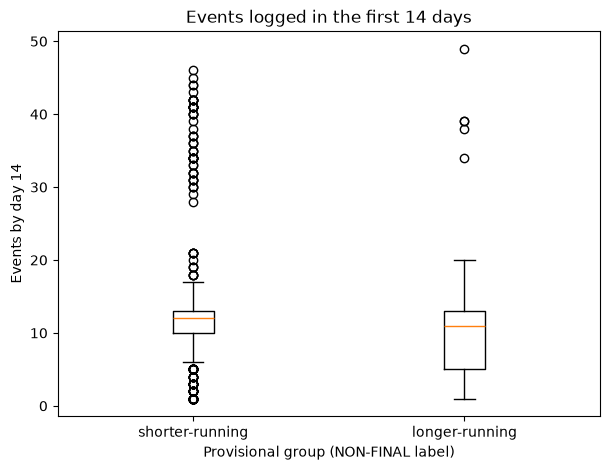

In [16]:
def group_boxplot(column, title, ylabel, filename):
    order = ["shorter-running", "longer-running"]
    plt.figure(figsize=(7, 5))
    plt.boxplot([features.loc[provisional_group == g, column] for g in order], tick_labels=order)
    plt.title(title)
    plt.xlabel("Provisional group (NON-FINAL label)")
    plt.ylabel(ylabel)
    plt.savefig(figures_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()


group_boxplot("event_count_14d", "Events logged in the first 14 days", "Events by day 14", "feature_event_count_14d.png")

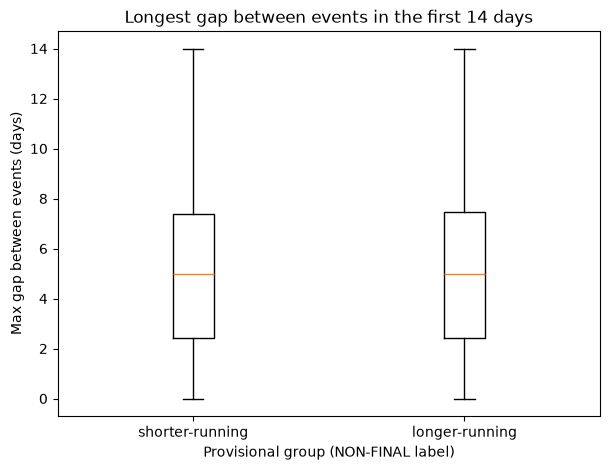

In [17]:
group_boxplot("max_inter_event_days", "Longest gap between events in the first 14 days", "Max gap between events (days)", "feature_max_gap_14d.png")

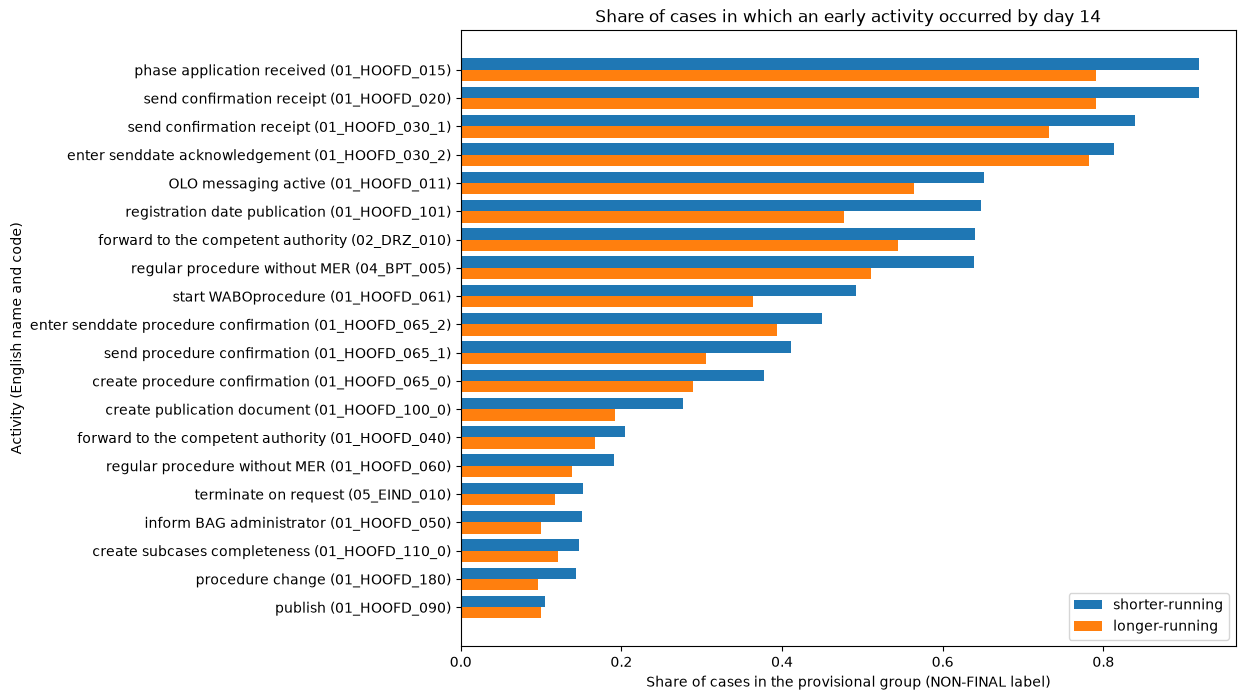

In [18]:
flag_columns = [F.ACTIVITY_FLAG_PREFIX + a for a in activity_codes]
flag_share = features[flag_columns].groupby(provisional_group).mean().T
flag_share.index = [f"{english_label[c.removeprefix(F.ACTIVITY_FLAG_PREFIX)]} ({c.removeprefix(F.ACTIVITY_FLAG_PREFIX)})" for c in flag_share.index]
flag_share = flag_share.sort_values("shorter-running")
positions = np.arange(len(flag_share))
bar_height = 0.4
plt.figure(figsize=(10, 8))
plt.barh(positions + bar_height / 2, flag_share["shorter-running"], height=bar_height, label="shorter-running")
plt.barh(positions - bar_height / 2, flag_share["longer-running"], height=bar_height, label="longer-running")
plt.yticks(positions, flag_share.index)
plt.title("Share of cases in which an early activity occurred by day 14")
plt.xlabel("Share of cases in the provisional group (NON-FINAL label)")
plt.ylabel("Activity (English name and code)")
plt.legend()
plt.savefig(figures_dir / "feature_early_activity_share.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the comparison (association, not causation).**

- **Less early activity.** Longer-running cases have logged fewer events by day 14 on average (about 10 vs 12.6), with fewer events in both the first week and the second week. The boxplot shows *where* that difference sits: a distinct cluster of shorter-running cases has very high early activity (roughly 28–46 events), and the middle half of the longer-running group reaches down to much lower counts (about 5 events), while the medians are close (11 vs 12).
- **Standard early steps happen less often.** For almost every selected activity, the share of cases that reached it by day 14 is lower in the longer-running group. The gap is largest for publication and procedure-start steps (e.g. *registration date publication*, *start WABOprocedure*). Longer-running cases seem to be further behind on the usual early path at day 14.
- **Waiting gaps:** the *mean* and *median* gap between events is somewhat longer for longer-running cases, but the *maximum* gap and the time since the last event are nearly the same in both groups (see the boxplot).
- **Rework is rare by day 14.** Repeated activities almost never occur this early; `activities_repeated_more_than_once_14d` is zero for every case. Rework seen in the full traces (`02_eda.ipynb`) happens later in the process.
- The groups **overlap heavily** on every single feature. Any predictive signal will come from combinations, and may be modest.

These observations are **not** used to select or drop features. The full retained set goes to modelling, where the label comes from the training period.

# 12. How this maps to SPAR

A future SPAR system could compute the **same kinds of features from its own event history at a fixed point in time**,
e.g. 14 days after a case is opened, using only what has already been recorded:

- **Actions already performed:** number of events, distinct steps, activity on each day.
- **Repetition / rework:** steps performed more than once.
- **Units/resources involved:** how many, and how often work changed hands.
- **Waiting time:** days since the last action and the longest pause so far.
- **Early process path:** which key steps have (or have not) happened yet, the first step, the latest step.
- **Context:** how many other cases were active recently.

The same point-in-time discipline applies: only data with a reliable recording time may be used, and final-state fields are excluded.

> This BPI-based pipeline is a **proof of concept** on public data from a Dutch municipality. Any model built on it would need to
> be **re-trained and re-validated on SPAR data**, and SPAR's own activity codes and fields would need the same point-in-time audit.

# 13. Summary

- 917 prediction-eligible cases (of 956 outcome-eligible; 39 finished by day 14), one row each.
- Predictors come only from the case ID, activity code, timestamp and resource of events at or before the 14-day snapshot, plus past-only workload and start-date calendar features.
- `planned` / `dueDate` / `dateFinished` / `dateStop` and all case-level attributes are excluded, because their write time is unknown or they are final-state.
- Automated leakage checks passed: snapshot bound, future-perturbation test, independent workload recomputation, no forbidden columns.
- Saved to `data/processed/case_features_14d.csv` (git-ignored) with the raw outcome duration and no label.

**Not done:** no model, no tuning, no train/test split, no final threshold or label.